In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

In [ ]:
df = pd.read_csv('Country-data.csv')
print('Shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicates:', df.duplicated().sum())
print('Unique countries:', df['country'].nunique())
df.head()

Shape: (167, 10)
Missing values: 0
Duplicates: 0
Unique countries: 167


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [32]:
df.describe().round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,38.27,41.11,6.82,46.89,17144.69,7.78,70.56,2.95,12964.16
std,40.33,27.41,2.75,24.21,19278.07,10.57,8.89,1.51,18328.70
min,2.60,0.11,1.81,0.07,609.00,-4.21,32.10,1.15,231.00
25%,8.25,23.80,4.92,30.20,3355.00,1.81,65.30,1.80,1330.00
50%,19.30,35.00,6.32,43.30,9960.00,5.39,73.10,2.41,4660.00
75%,62.10,51.35,8.60,58.75,22800.00,10.75,76.80,3.88,14050.00
max,208.00,200.00,17.90,174.00,125000.00,104.00,82.80,7.49,105000.00


In [ ]:
# Convert % variables to absolute values (multiply by gdpp / 100)
for col in ['exports', 'health', 'imports']:
    df[col + '_abs'] = df[col] * df['gdpp'] / 100

numeric_cols = ['child_mort', 'exports_abs', 'health_abs', 'imports_abs',
                'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
df[['country'] + numeric_cols].head()

,country,child_mort,exports_abs,health_abs,imports_abs,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,55.30,41.9174,248.297,1610,9.44,56.2,5.82,553
1,Albania,16.6,1145.20,267.8950,1987.740,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,1712.64,185.9820,1400.440,12900,16.10,76.5,2.89,4460
3,Angola,119.0,2199.19,100.6050,1514.370,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,5551.00,735.6600,7185.800,19100,1.44,76.8,2.13,12200


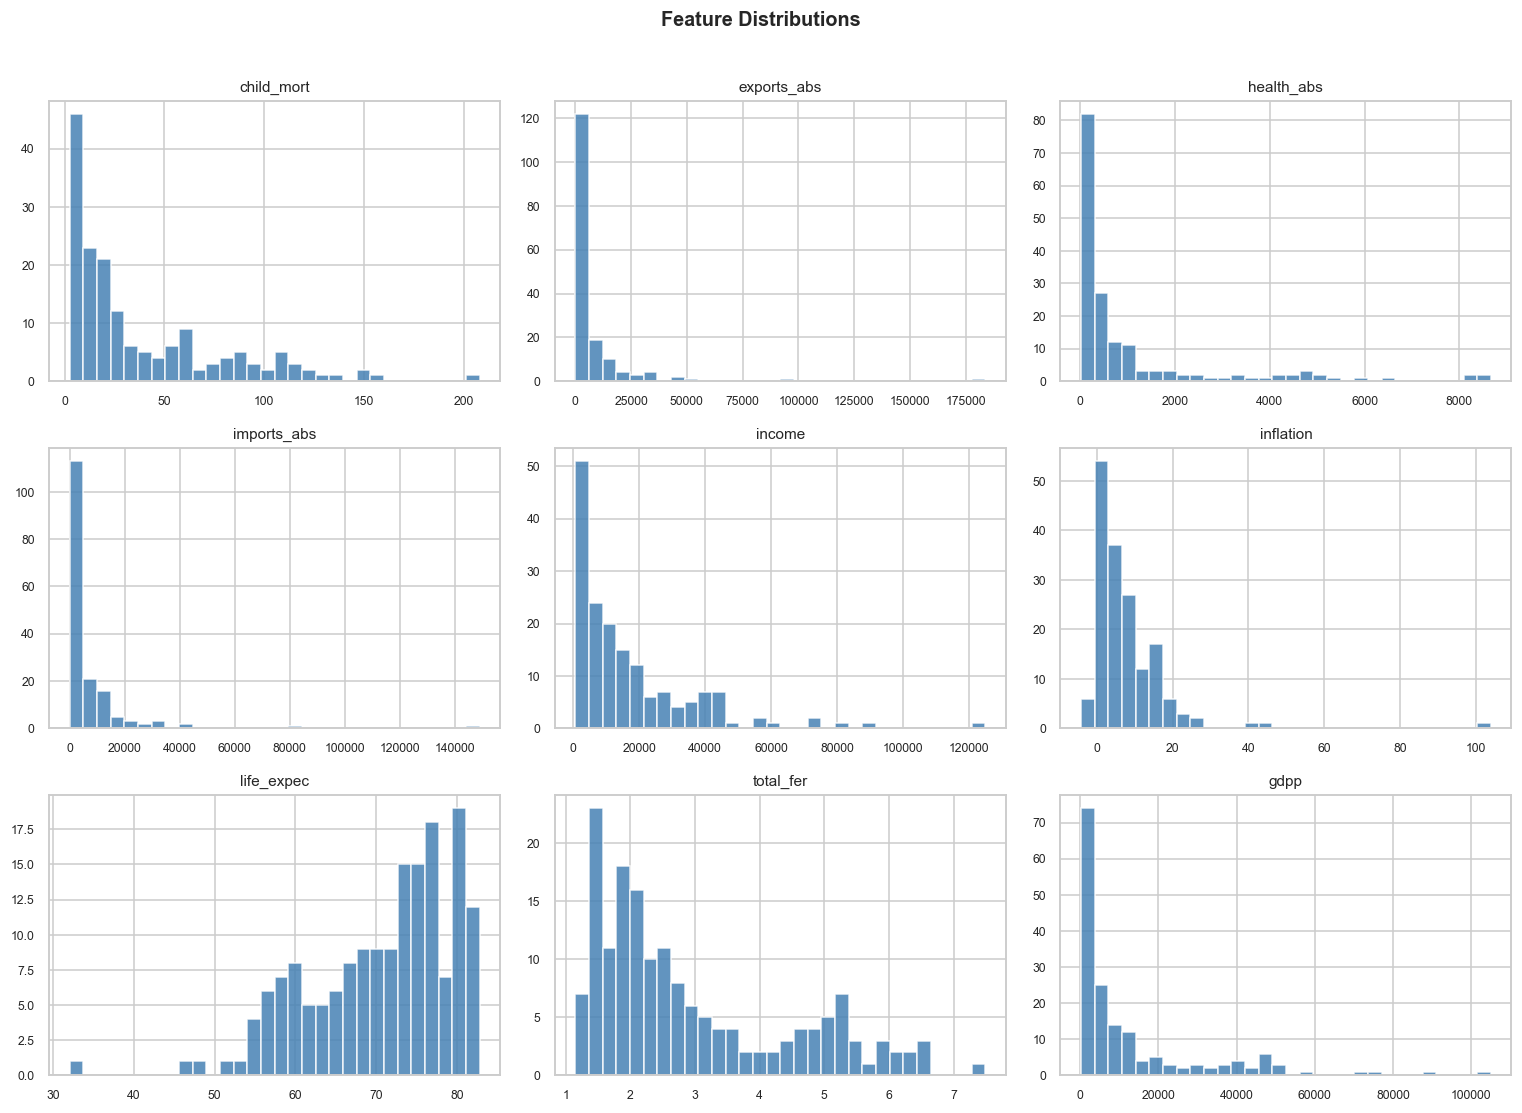

In [34]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(df[col], bins=30, color='steelblue', edgecolor='white', alpha=0.85)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
plt.suptitle('Feature Distributions', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

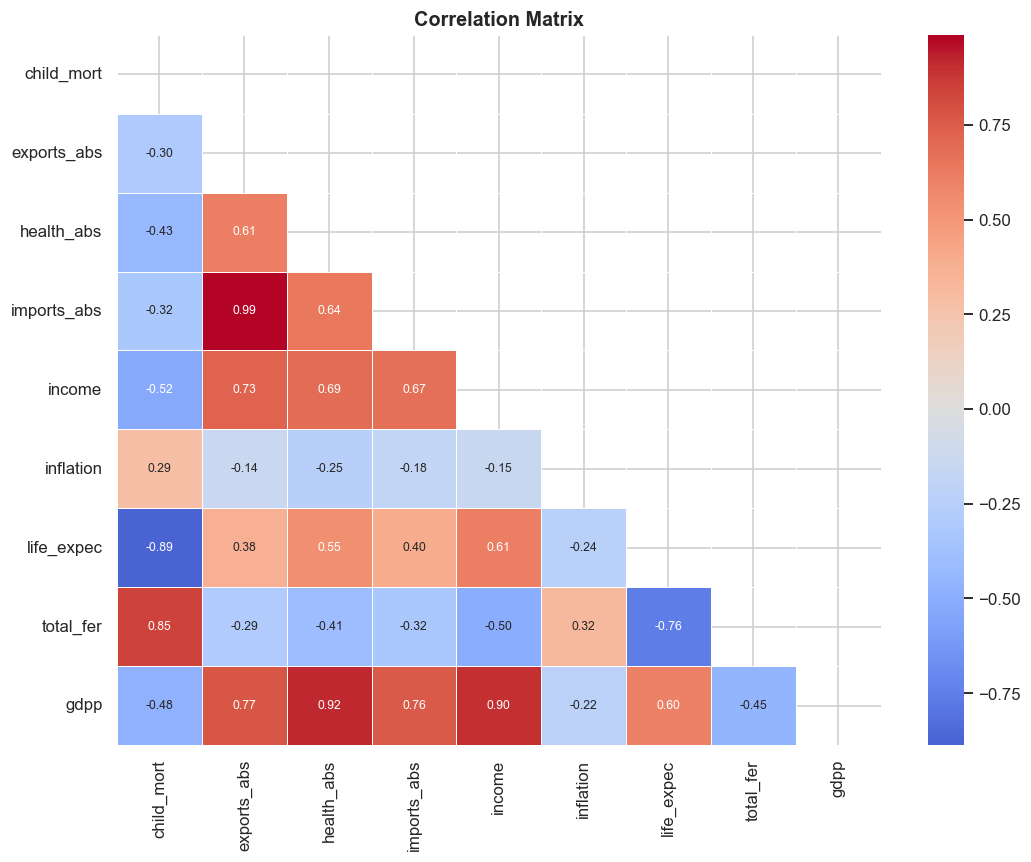

In [ ]:
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

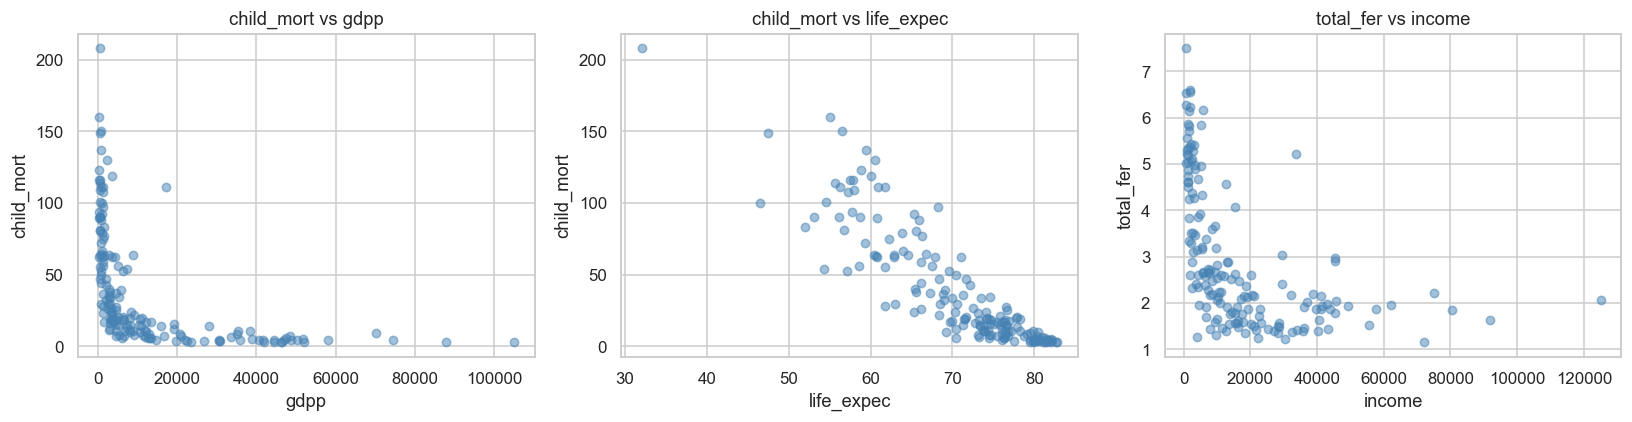

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pairs = [('gdpp', 'child_mort'), ('life_expec', 'child_mort'), ('income', 'total_fer')]
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df[x], df[y], alpha=0.5, s=30, color='steelblue')
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f'{y} vs {x}')
plt.tight_layout()
plt.show()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[numeric_cols])
print('Scaled shape:', X_scaled.shape)
print('Means (~0):', X_scaled.mean(axis=0).round(4))
print('Stds  (~1):', X_scaled.std(axis=0).round(4))

Scaled shape: (167, 9)
Means (~0): [-0.  0. -0.  0. -0. -0.  0.  0.  0.]
Stds  (~1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
pca_full = PCA()
pca_full.fit(X_scaled)
evr   = pca_full.explained_variance_ratio_
cumev = np.cumsum(evr)

for i, (e, c) in enumerate(zip(evr, cumev)):
    print(f'PC{i+1}: {e*100:.2f}%  |  cumulative: {c*100:.2f}%')

PC1: 58.94%  |  cumulative: 58.94%
PC2: 18.45%  |  cumulative: 77.38%
PC3: 9.91%  |  cumulative: 87.29%
PC4: 6.07%  |  cumulative: 93.37%
PC5: 3.03%  |  cumulative: 96.40%
PC6: 2.46%  |  cumulative: 98.86%
PC7: 0.94%  |  cumulative: 99.79%
PC8: 0.16%  |  cumulative: 99.95%
PC9: 0.05%  |  cumulative: 100.00%


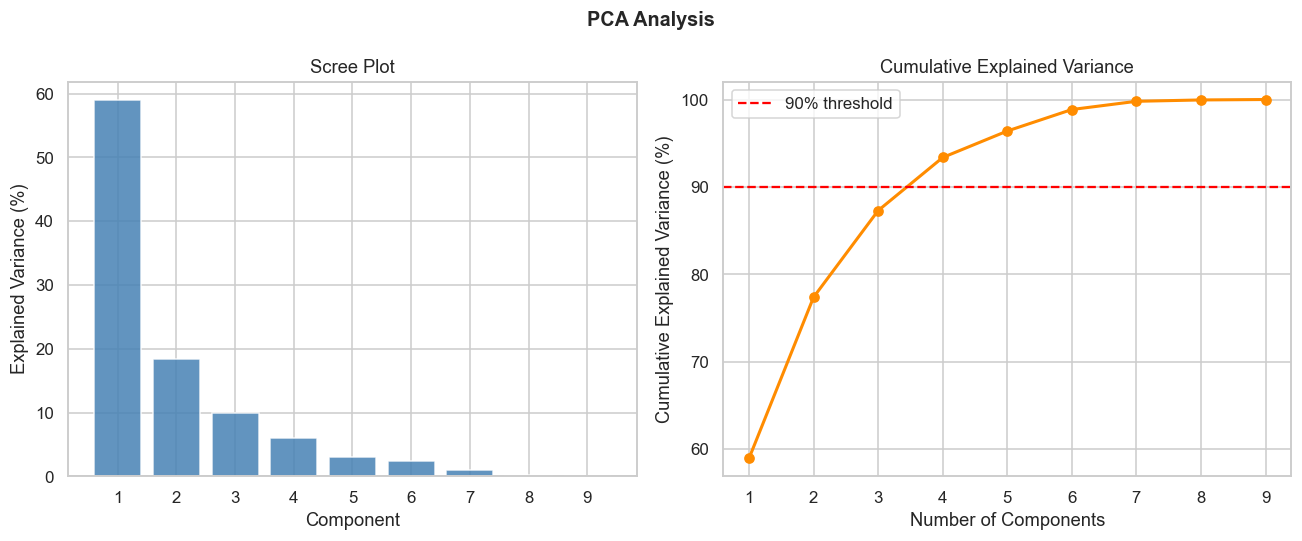

Retaining 4 PCs (93.4% cumulative variance)


In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(range(1, len(evr)+1), evr*100, color='steelblue', alpha=0.85)
ax1.set_xlabel('Component'); ax1.set_ylabel('Explained Variance (%)')
ax1.set_title('Scree Plot'); ax1.set_xticks(range(1, len(evr)+1))

ax2.plot(range(1, len(cumev)+1), cumev*100, 'o-', color='darkorange', lw=2)
ax2.axhline(90, ls='--', color='red', lw=1.5, label='90% threshold')
ax2.set_xlabel('Number of Components'); ax2.set_ylabel('Cumulative Explained Variance (%)')
ax2.set_title('Cumulative Explained Variance'); ax2.legend()
ax2.set_xticks(range(1, len(cumev)+1))

plt.suptitle('PCA Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

n_comp = 4
print(f'Retaining {n_comp} PCs ({cumev[n_comp-1]*100:.1f}% cumulative variance)')

In [ ]:
pca = PCA(n_components=n_comp)
X_pca = pca.fit_transform(X_scaled)

pc_cols = [f'PC{i+1}' for i in range(n_comp)]
df_pca  = pd.DataFrame(X_pca, columns=pc_cols)
df_pca['country'] = df['country'].values
df_pca.head()

,PC1,PC2,PC3,PC4,country
0,-2.635575,1.472267,-0.549489,0.242326,Afghanistan
1,-0.024206,-1.429892,-0.014123,-0.450645,Albania
2,-0.459557,-0.675495,0.959355,-0.218456,Algeria
3,-2.722630,2.172332,0.600215,0.433978,Angola
4,0.648597,-1.023437,-0.257430,-0.289201,Antigua and Barbuda


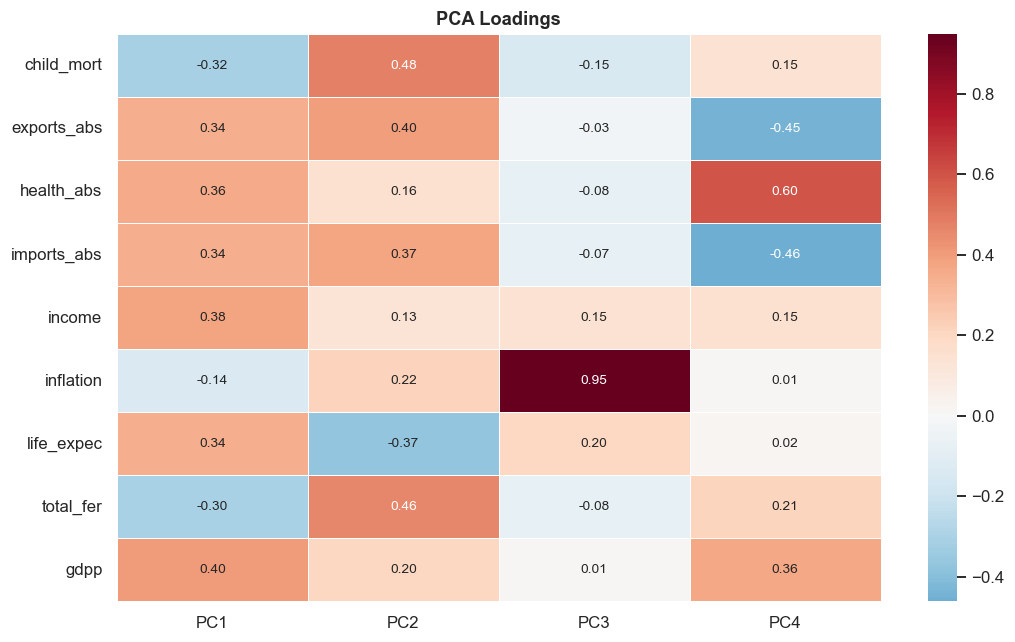

In [41]:
loadings = pd.DataFrame(pca.components_.T, index=numeric_cols, columns=pc_cols)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, linewidths=0.5, annot_kws={'size': 9})
ax.set_title('PCA Loadings', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Remove outliers: points beyond 1.5*IQR in any PC dimension
mask_ok = pd.Series([True]*len(df_pca), index=df_pca.index)
for col in pc_cols:
    Q1, Q3 = df_pca[col].quantile(0.25), df_pca[col].quantile(0.75)
    IQR = Q3 - Q1
    mask_ok &= (df_pca[col] >= Q1 - 1.5*IQR) & (df_pca[col] <= Q3 + 1.5*IQR)

df_out      = df_pca[~mask_ok].copy()
df_clean    = df_pca[mask_ok].copy().reset_index(drop=True)
df_out_orig = df[~mask_ok].copy().reset_index(drop=True)
df_main     = df[mask_ok].copy().reset_index(drop=True)

print(f'Outliers removed ({(~mask_ok).sum()}): {list(df_out["country"])}')
print(f'Remaining for clustering: {len(df_clean)}')

Outliers removed (26): ['Argentina', 'Australia', 'Brunei', 'Canada', 'Central African Republic', 'Denmark', 'France', 'Germany', 'Haiti', 'Ireland', 'Japan', 'Luxembourg', 'Malta', 'Mongolia', 'Netherlands', 'Nigeria', 'Norway', 'Qatar', 'Saudi Arabia', 'Singapore', 'Sri Lanka', 'Sweden', 'Switzerland', 'Timor-Leste', 'United States', 'Venezuela']
Remaining for clustering: 141


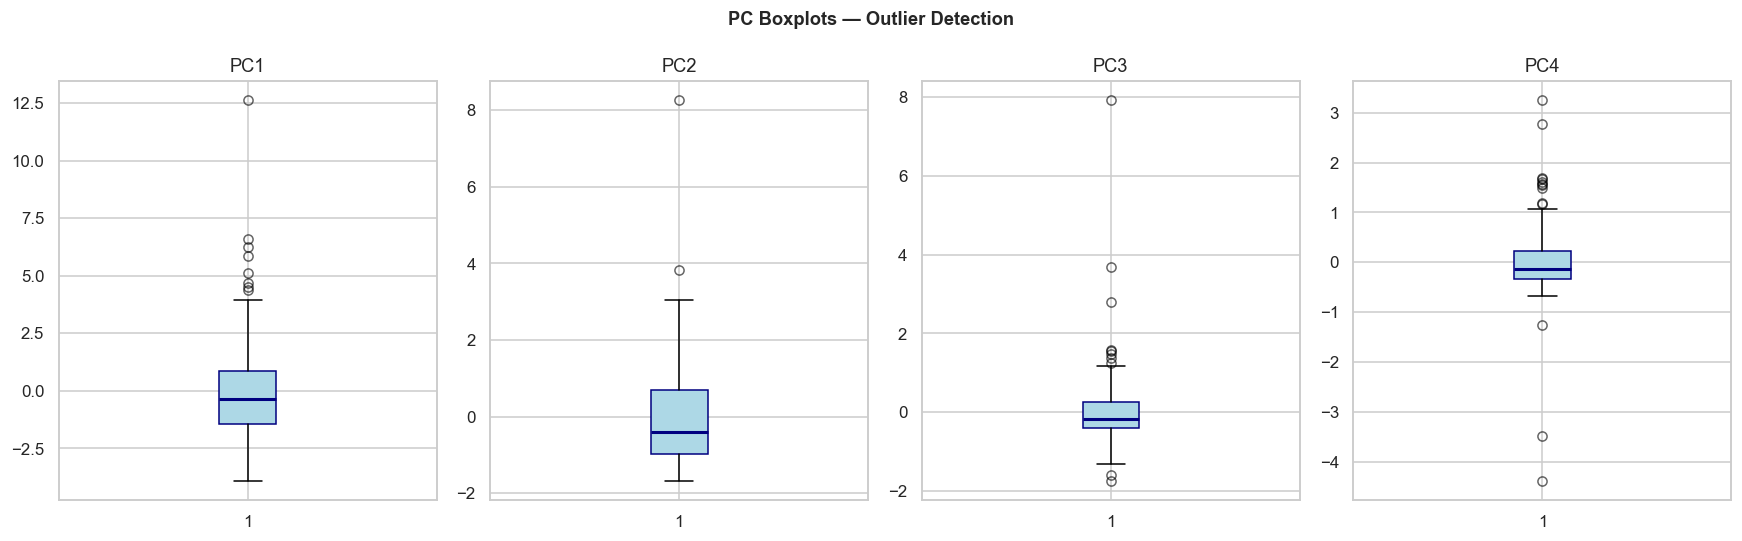

Cleaned data shape: (141, 4)


In [43]:
fig, axes = plt.subplots(1, n_comp, figsize=(4*n_comp, 5))
for ax, col in zip(axes, pc_cols):
    ax.boxplot(df_pca[col], patch_artist=True,
               boxprops=dict(facecolor='lightblue', color='navy'),
               medianprops=dict(color='navy', lw=2),
               flierprops=dict(marker='o', color='red', alpha=0.6))
    ax.set_title(col)
plt.suptitle('PC Boxplots — Outlier Detection', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

X_clean = df_clean[pc_cols].values
print('Cleaned data shape:', X_clean.shape)

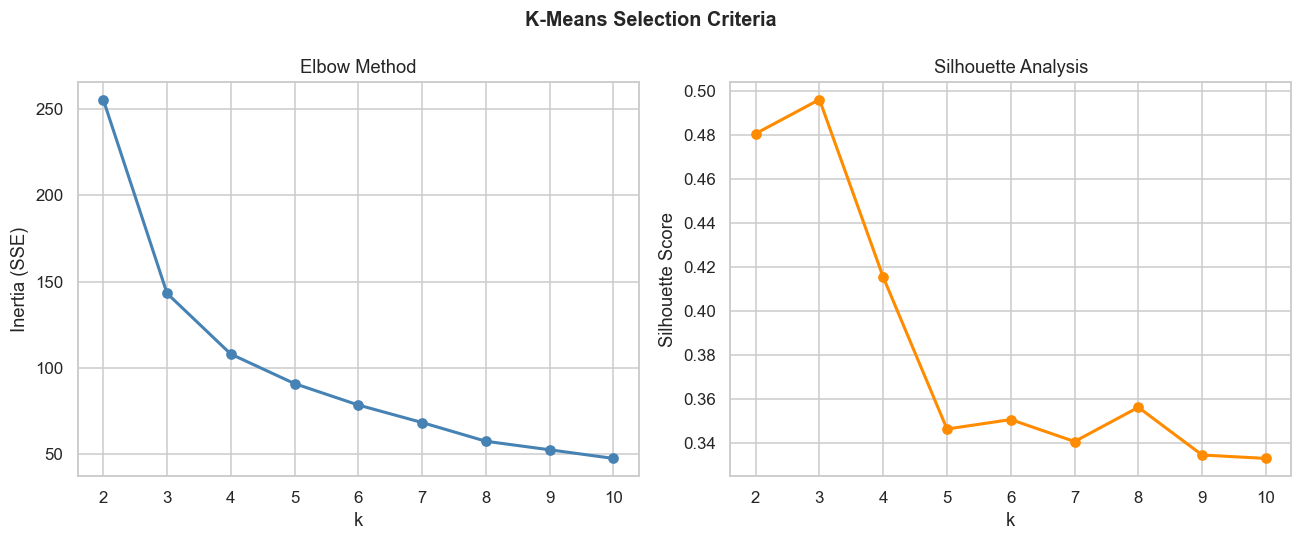

Best k by silhouette: 3  (score=0.4961)
  k=2: 0.4806
  k=3: 0.4961
  k=4: 0.4154
  k=5: 0.3465
  k=6: 0.3508
  k=7: 0.3408
  k=8: 0.3563
  k=9: 0.3347
  k=10: 0.3331


In [ ]:
k_range = range(2, 11)
inertias, sils = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_clean)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_clean, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(list(k_range), inertias, 'o-', color='steelblue', lw=2)
ax1.set_xlabel('k'); ax1.set_ylabel('Inertia (SSE)')
ax1.set_title('Elbow Method'); ax1.set_xticks(list(k_range))

ax2.plot(list(k_range), sils, 'o-', color='darkorange', lw=2)
ax2.set_xlabel('k'); ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis'); ax2.set_xticks(list(k_range))

plt.suptitle('K-Means Selection Criteria', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sils))]
print(f'Best k by silhouette: {best_k}  (score={max(sils):.4f})')
for k, s in zip(k_range, sils):
    print(f'  k={k}: {s:.4f}')

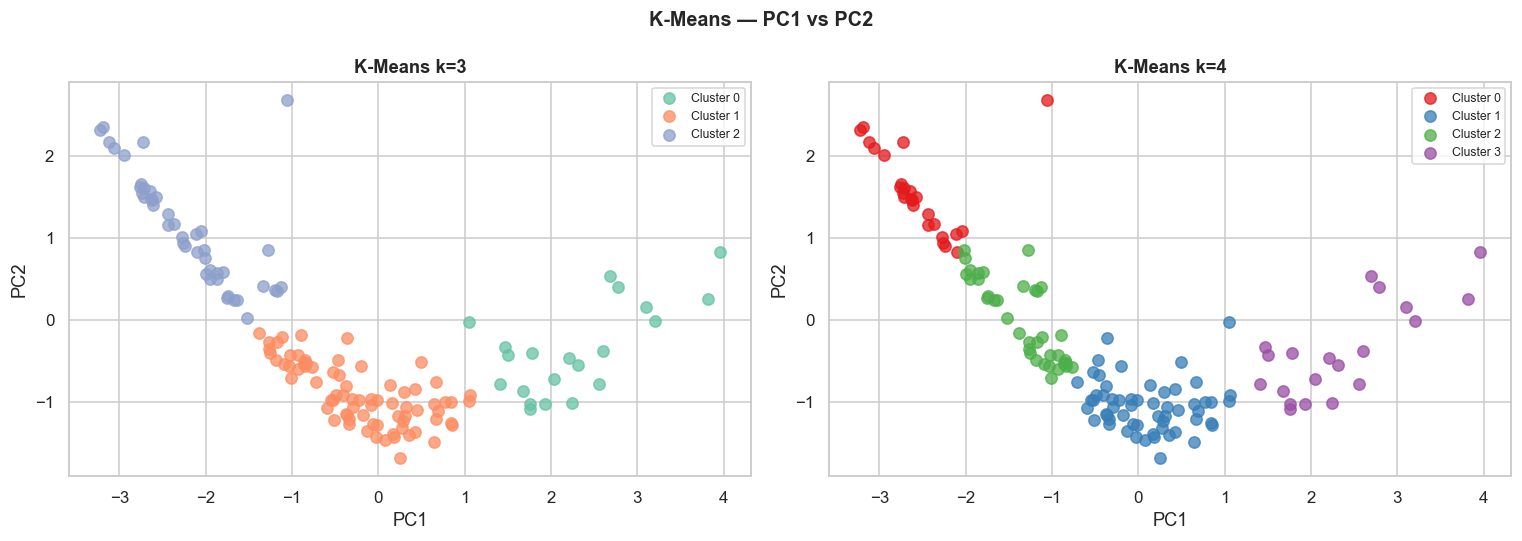

In [45]:
for k in [3, 4]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    df_clean[f'km{k}'] = km.fit_predict(X_clean)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, k, pal in zip(axes, [3, 4], ['Set2', 'Set1']):
    colors = sns.color_palette(pal, k)
    for c in range(k):
        mask = df_clean[f'km{k}'] == c
        ax.scatter(X_clean[mask, 0], X_clean[mask, 1],
                   color=colors[c], label=f'Cluster {c}', s=55, alpha=0.75)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.set_title(f'K-Means k={k}', fontweight='bold')
    ax.legend(fontsize=8)
plt.suptitle('K-Means — PC1 vs PC2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
original_cols = ['child_mort', 'exports_abs', 'health_abs', 'imports_abs',
                 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']

for col in original_cols:
    df_main[col] = df[mask_ok][col].values
df_main['km3'] = df_clean['km3'].values

cluster_means_km = df_main.groupby('km3')[original_cols].mean().round(1)
print('K-Means (k=3) Cluster Means:')
cluster_means_km

K-Means (k=3) Cluster Means:


,child_mort,exports_abs,health_abs,imports_abs,income,inflation,life_expec,total_fer,gdpp
km3,,,,,,,,,
0,5.8,15073.8,2557.9,13801.2,36866.7,3.2,79.1,1.8,31081.0
1,22.4,2616.8,383.5,2858.4,11405.5,6.2,72.9,2.3,5890.9
2,87.4,940.3,113.7,857.8,4038.3,9.9,59.8,5.0,1922.8


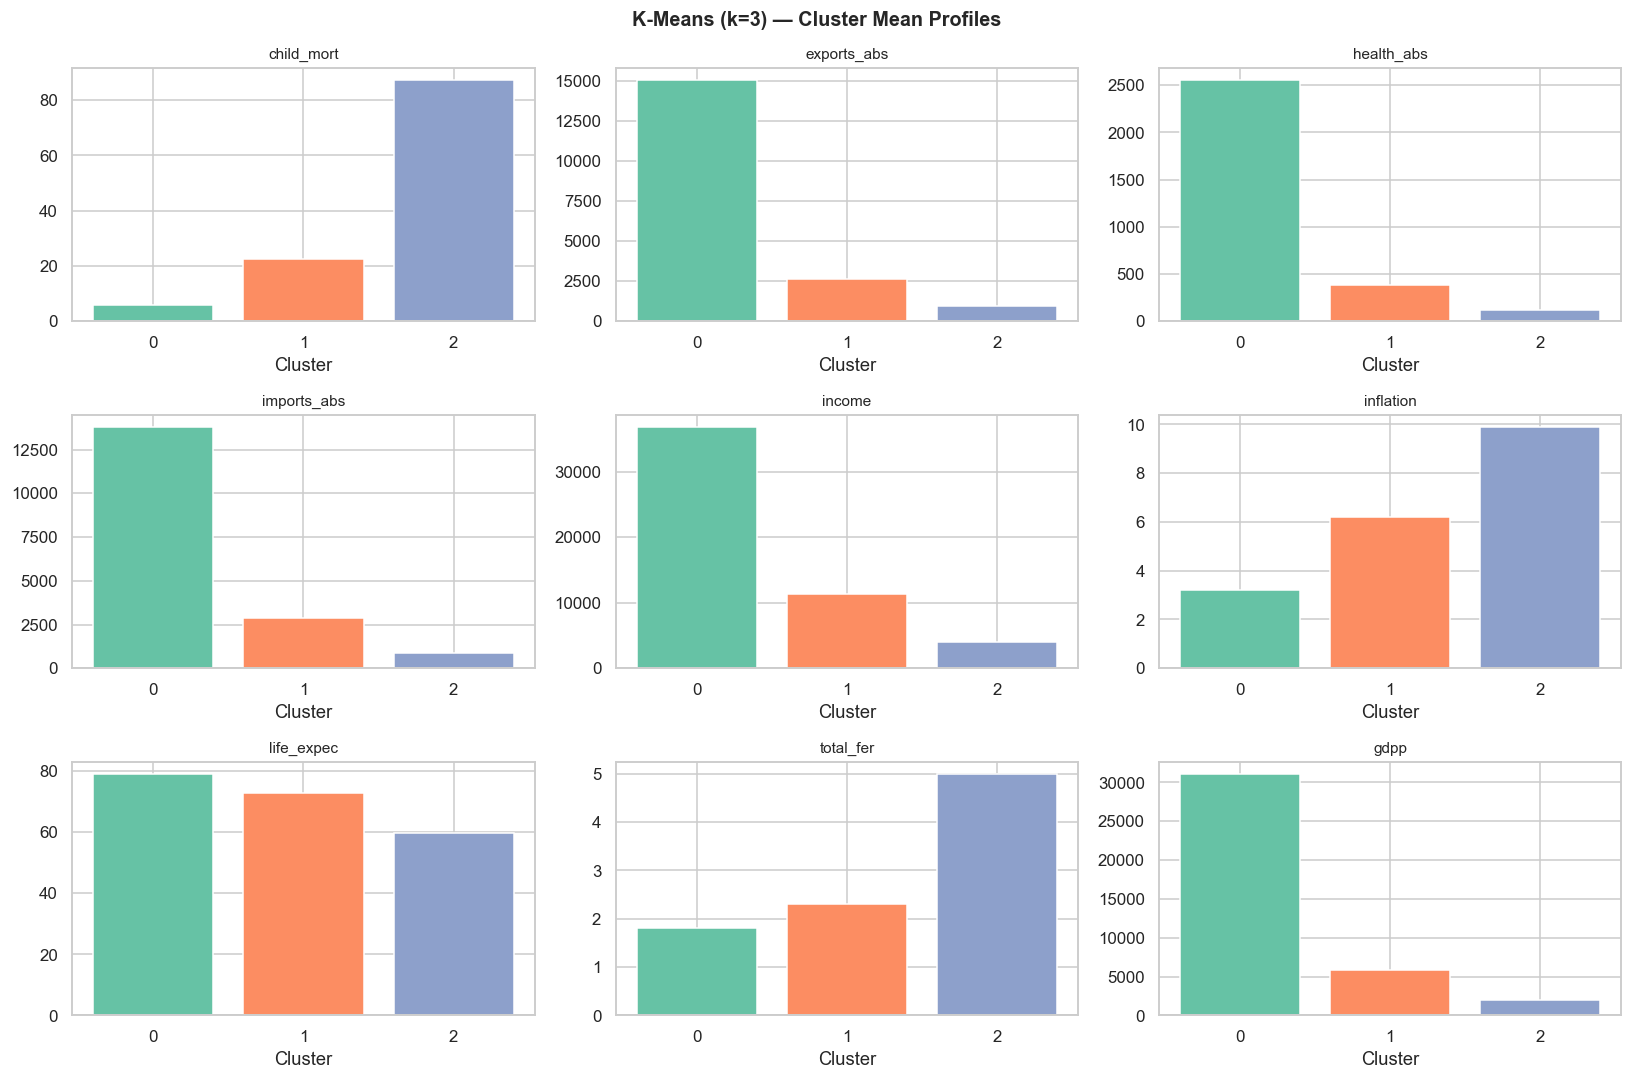

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
colors = sns.color_palette('Set2', 3)
for ax, col in zip(axes.flatten(), original_cols):
    vals = cluster_means_km[col]
    ax.bar(vals.index, vals.values, color=colors[:3])
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Cluster'); ax.set_xticks(vals.index)
plt.suptitle('K-Means (k=3) — Cluster Mean Profiles', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
for c in range(3):
    countries = df_main[df_main['km3'] == c]['country'].tolist()
    print(f'\n--- Cluster {c} ({len(countries)} countries) ---')
    print(', '.join(countries))


--- Cluster 0 (21 countries) ---
Austria, Bahamas, Bahrain, Belgium, Cyprus, Czech Republic, Finland, Greece, Iceland, Israel, Italy, Kuwait, New Zealand, Oman, Portugal, Slovak Republic, Slovenia, South Korea, Spain, United Arab Emirates, United Kingdom

--- Cluster 1 (76 countries) ---
Albania, Algeria, Antigua and Barbuda, Armenia, Azerbaijan, Bangladesh, Barbados, Belarus, Belize, Bhutan, Bolivia, Bosnia and Herzegovina, Brazil, Bulgaria, Cambodia, Cape Verde, Chile, China, Colombia, Costa Rica, Croatia, Dominican Republic, Ecuador, Egypt, El Salvador, Estonia, Fiji, Georgia, Grenada, Guatemala, Guyana, Hungary, India, Indonesia, Iran, Jamaica, Jordan, Kazakhstan, Kyrgyz Republic, Latvia, Lebanon, Libya, Lithuania, Macedonia, FYR, Malaysia, Maldives, Mauritius, Micronesia, Fed. Sts., Moldova, Montenegro, Morocco, Myanmar, Nepal, Panama, Paraguay, Peru, Philippines, Poland, Romania, Russia, Samoa, Serbia, Seychelles, St. Vincent and the Grenadines, Suriname, Tajikistan, Thailand, T

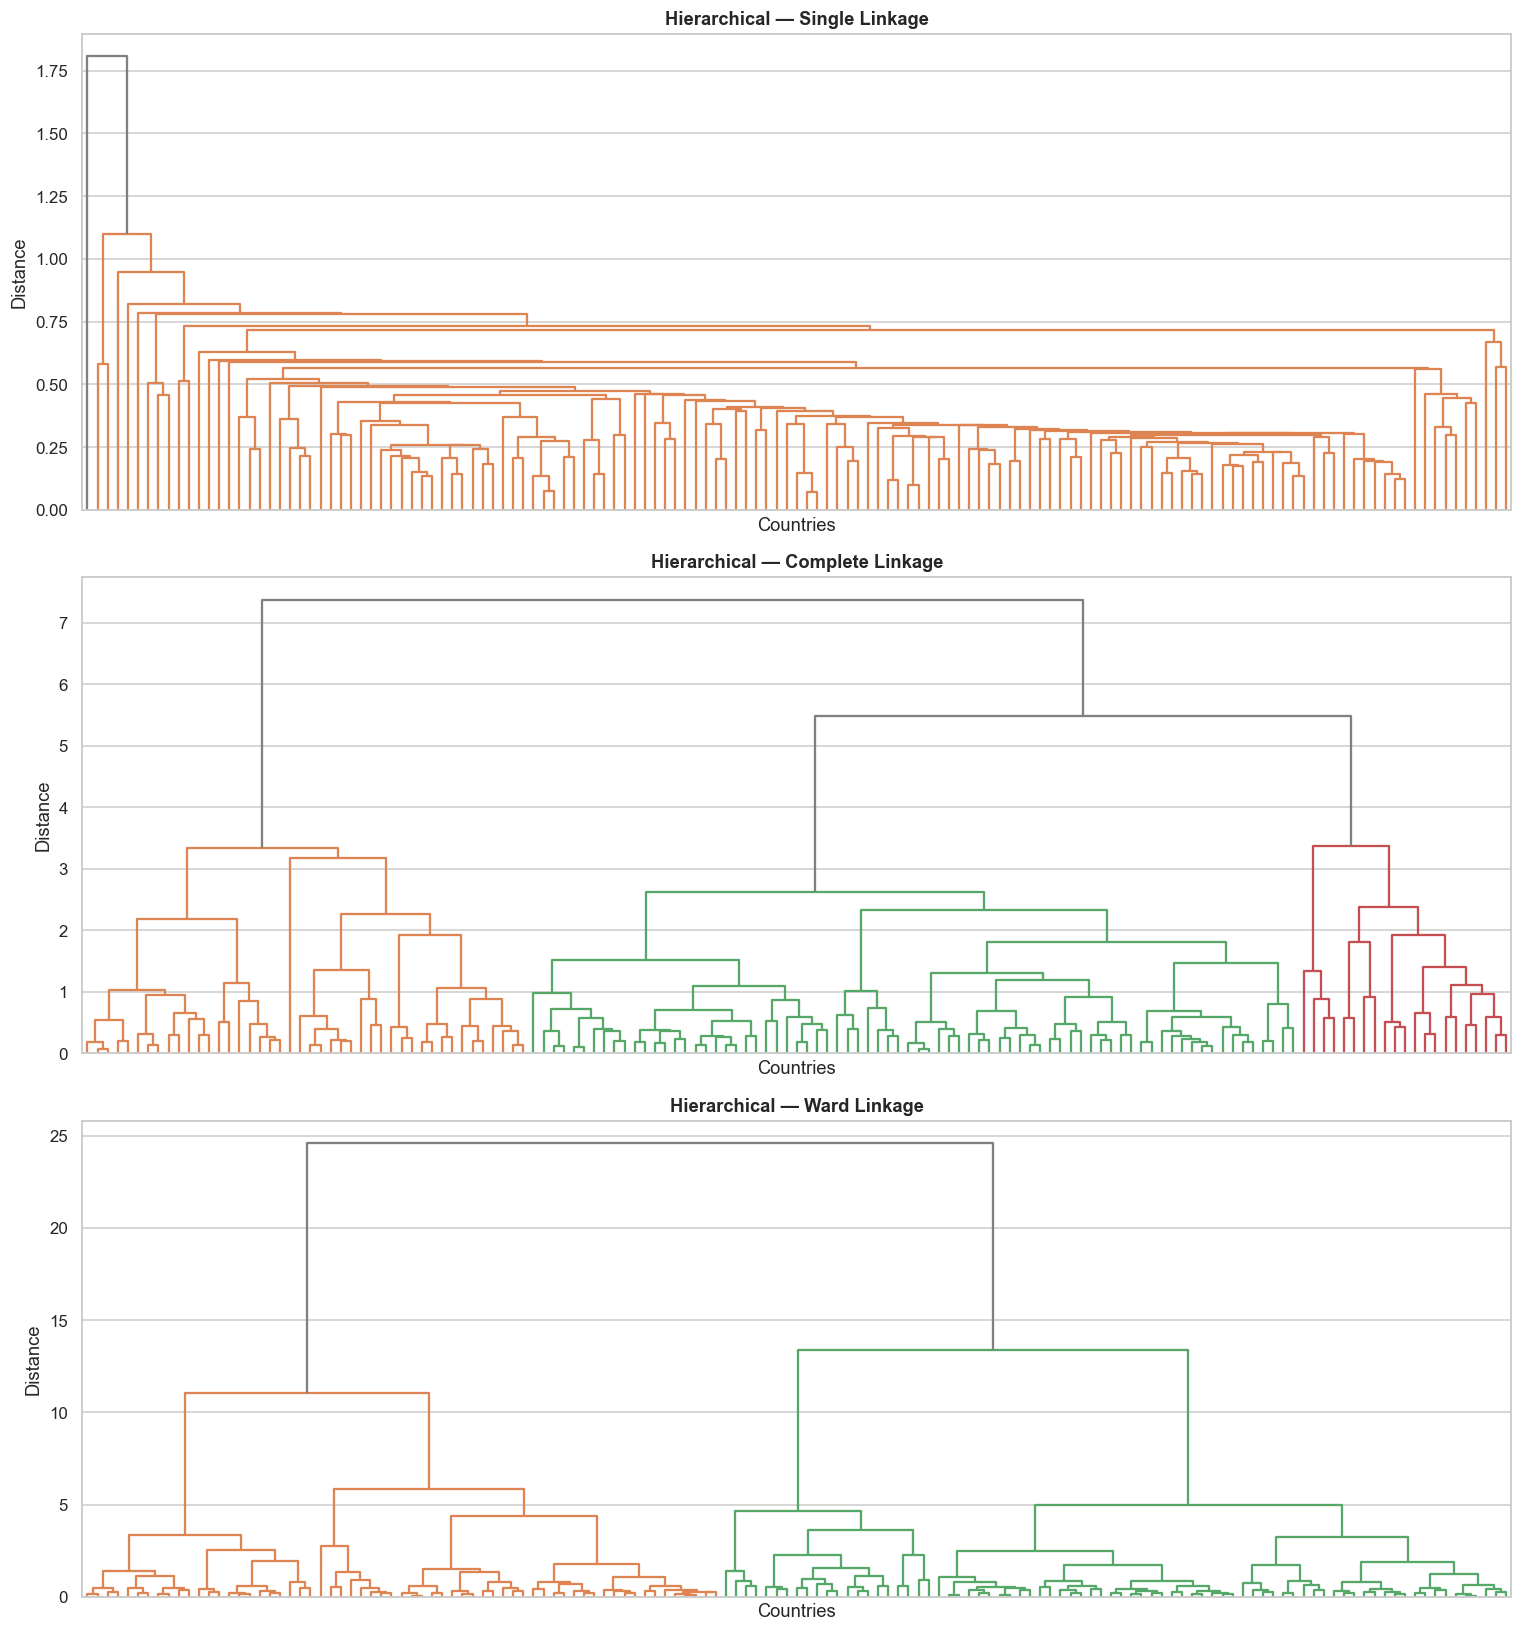

In [49]:
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for ax, method in zip(axes, ['single', 'complete', 'ward']):
    Z = linkage(X_clean, method=method, metric='euclidean')
    dendrogram(Z, ax=ax, no_labels=True,
               color_threshold=0.7*max(Z[:, 2]),
               above_threshold_color='grey')
    ax.set_title(f'Hierarchical — {method.capitalize()} Linkage', fontweight='bold')
    ax.set_xlabel('Countries'); ax.set_ylabel('Distance')
plt.tight_layout()
plt.show()

In [ ]:
Z_ward = linkage(X_clean, method='ward', metric='euclidean')
hc_labels = fcluster(Z_ward, t=3, criterion='maxclust') - 1

df_clean['hc'] = hc_labels
df_main['hc']  = hc_labels

cluster_means_hc = df_main.groupby('hc')[original_cols].mean().round(1)
print('Ward HC (k=3) Cluster Means:')
cluster_means_hc

Ward HC (k=3) Cluster Means:


,child_mort,exports_abs,health_abs,imports_abs,income,inflation,life_expec,total_fer,gdpp
hc,,,,,,,,,
0,73.2,907.6,115.8,942.8,4309.0,8.8,62.4,4.4,2006.0
1,5.8,15073.8,2557.9,13801.2,36866.7,3.2,79.1,1.8,31081.0
2,16.5,3211.8,471.1,3431.4,13562.1,6.1,74.4,2.0,7121.8


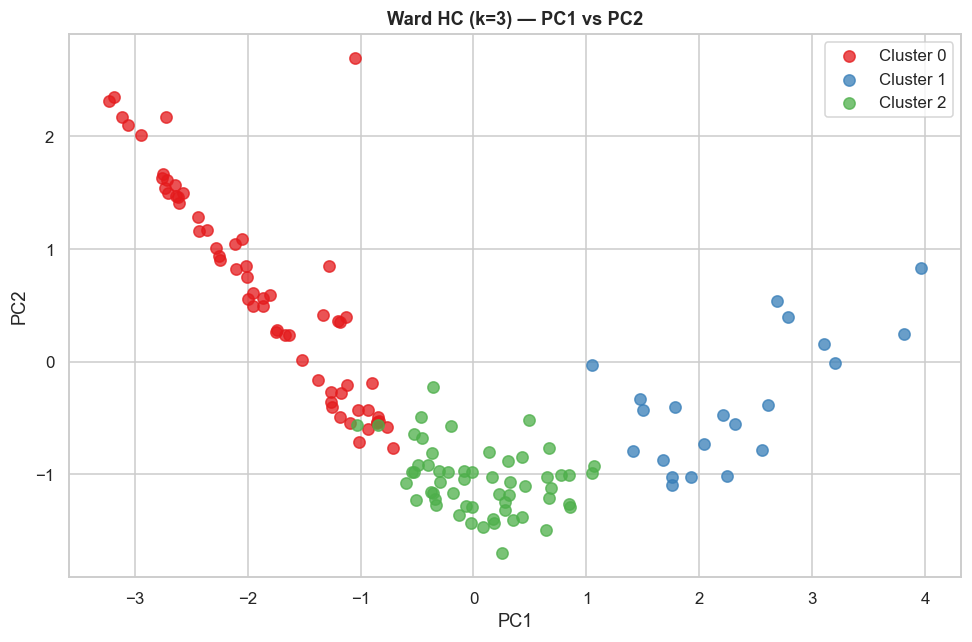

In [51]:
fig, ax = plt.subplots(figsize=(9, 6))
palette = sns.color_palette('Set1', 3)
for c in range(3):
    mask = hc_labels == c
    ax.scatter(X_clean[mask, 0], X_clean[mask, 1],
               color=palette[c], label=f'Cluster {c}', s=55, alpha=0.75)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('Ward HC (k=3) — PC1 vs PC2', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
ari = adjusted_rand_score(df_main['km3'], df_main['hc'])
print(f'Adjusted Rand Index (K-Means vs Ward HC): {ari:.3f}')
pd.crosstab(df_main['km3'], df_main['hc'], rownames=['K-Means'], colnames=['HC Ward'])

Adjusted Rand Index (K-Means vs Ward HC): 0.593


HC Ward,0,1,2
K-Means,,,
0,0,21,0
1,19,0,57
2,44,0,0


GMM silhouette: 0.3639


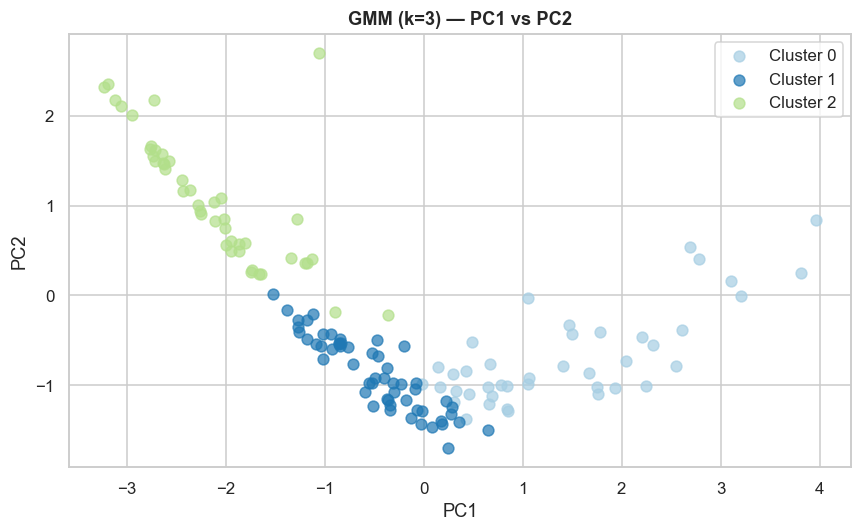

In [53]:
gmm = GaussianMixture(n_components=3, random_state=42, n_init=5)
gmm_labels = gmm.fit_predict(X_clean)
print(f'GMM silhouette: {silhouette_score(X_clean, gmm_labels):.4f}')

fig, ax = plt.subplots(figsize=(8, 5))
palette = sns.color_palette('Paired', 3)
for c in range(3):
    mask = gmm_labels == c
    ax.scatter(X_clean[mask, 0], X_clean[mask, 1],
               color=palette[c], label=f'Cluster {c}', s=50, alpha=0.7)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('GMM (k=3) — PC1 vs PC2', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
dbscan = DBSCAN(eps=1.0, min_samples=5)
db_labels = dbscan.fit_predict(X_clean)
n_db    = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()
print(f'DBSCAN: {n_db} cluster(s), {n_noise} noise points')
print('=> DBSCAN rejected: merges most countries into one cluster, not useful here.')

DBSCAN: 1 cluster(s), 5 noise points
=> DBSCAN rejected: merges most countries into one cluster, not useful here.


In [ ]:
X_out    = df_pca[~mask_ok][pc_cols].values.copy()
km_out   = KMeans(n_clusters=2, random_state=42, n_init=10)
out_labs = km_out.fit_predict(X_out)

df_out_orig['cluster'] = out_labs
print('Outlier cluster means:')
print(df_out_orig.groupby('cluster')[['child_mort','income','gdpp','life_expec','total_fer']].mean().round(1))

print('\nCountries per outlier cluster:')
for c in range(2):
    print(f'  Cluster {c}:', list(df_out_orig[df_out_orig['cluster']==c]['country']))

Outlier cluster means:
         child_mort   income     gdpp  life_expec  total_fer
cluster                                                     
0               5.0  55188.2  54376.5        80.7        1.7
1              70.5  11806.4   6177.6        64.2        3.7

Countries per outlier cluster:
  Cluster 0: ['Australia', 'Brunei', 'Canada', 'Denmark', 'France', 'Germany', 'Ireland', 'Japan', 'Luxembourg', 'Malta', 'Netherlands', 'Norway', 'Qatar', 'Singapore', 'Sweden', 'Switzerland', 'United States']
  Cluster 1: ['Argentina', 'Central African Republic', 'Haiti', 'Mongolia', 'Nigeria', 'Saudi Arabia', 'Sri Lanka', 'Timor-Leste', 'Venezuela']


In [ ]:
high_need_out = df_out_orig[
    (df_out_orig['child_mort'] > 50) |
    (df_out_orig['gdpp'] < 3000) |
    (df_out_orig['life_expec'] < 65)
][['country', 'child_mort', 'income', 'gdpp', 'life_expec', 'total_fer']]

print('High-need countries from outlier group:')
print(high_need_out.to_string(index=False))

High-need countries from outlier group:
                 country  child_mort  income  gdpp  life_expec  total_fer
Central African Republic       149.0     888   446        47.5       5.21
                   Haiti       208.0    1500   662        32.1       3.33
                Mongolia        26.1    7710  2650        66.2       2.64
                 Nigeria       130.0    5150  2330        60.5       5.84
               Sri Lanka        11.2    8560  2810        74.4       2.20
             Timor-Leste        62.6    1850  3600        71.1       6.23


In [57]:
need_cluster = cluster_means_km['child_mort'].idxmax()

final = df_main[df_main['km3'] == need_cluster][
    ['country', 'child_mort', 'income', 'gdpp', 'life_expec', 'total_fer']
].sort_values('child_mort', ascending=False).reset_index(drop=True)

print(f'High-need cluster: {need_cluster}')
print(f'Cluster mean profile:\n{cluster_means_km.loc[need_cluster]}')
print(f'\nFinal recommended countries ({len(final)}):')
final

High-need cluster: 2
Cluster mean profile:
child_mort       87.4
exports_abs     940.3
health_abs      113.7
imports_abs     857.8
income         4038.3
inflation         9.9
life_expec       59.8
total_fer         5.0
gdpp           1922.8
Name: 2, dtype: float64

Final recommended countries (44):


,country,child_mort,income,gdpp,life_expec,total_fer
0,Sierra Leone,160.0,1220,399,55.0,5.20
1,Chad,150.0,1930,897,56.5,6.59
2,Mali,137.0,1870,708,59.5,6.55
3,Niger,123.0,814,348,58.8,7.49
4,Angola,119.0,5900,3530,60.1,6.16
5,"Congo, Dem. Rep.",116.0,609,334,57.5,6.54
6,Burkina Faso,116.0,1430,575,57.9,5.87
7,Guinea-Bissau,114.0,1390,547,55.6,5.05
8,Equatorial Guinea,111.0,33700,17100,60.9,5.21
9,Cote d'Ivoire,111.0,2690,1220,56.3,5.27


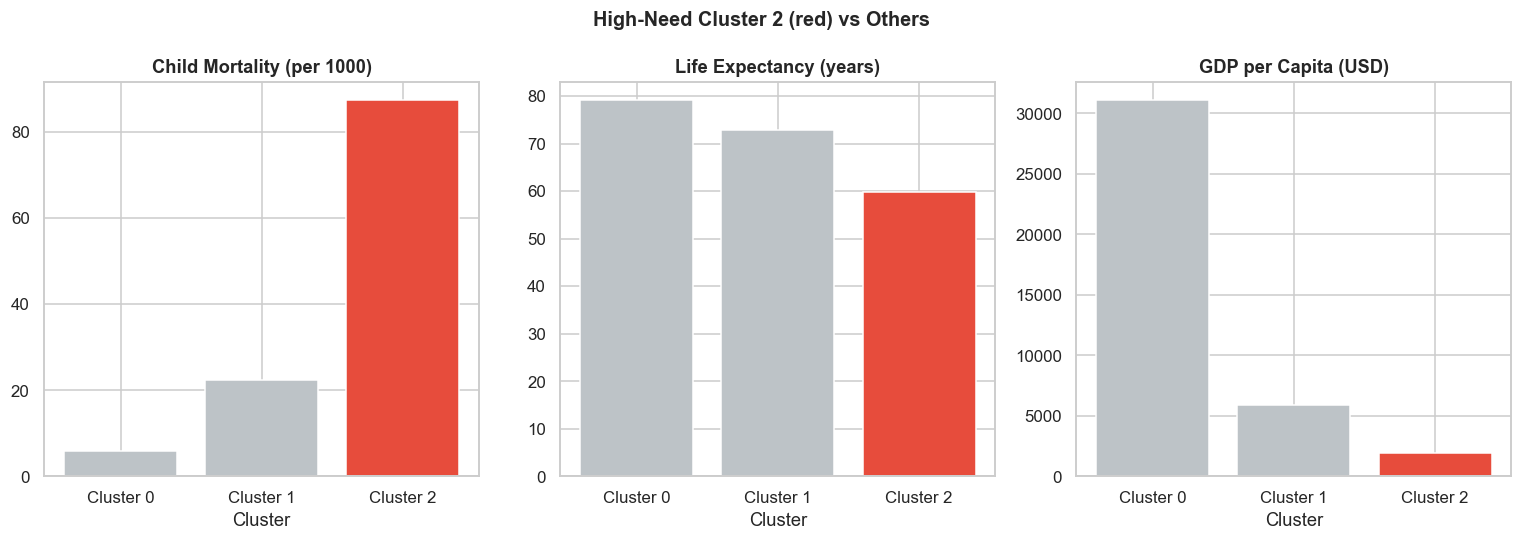

Total countries recommended for priority aid: 44
Sierra Leone, Chad, Mali, Niger, Angola, Congo, Dem. Rep., Burkina Faso, Guinea-Bissau, Equatorial Guinea, Cote d'Ivoire, Benin, Guinea, Cameroon, Mozambique, Lesotho, Mauritania, Burundi, Pakistan, Malawi, Togo, Afghanistan, Liberia, Comoros, Zambia, Uganda, Gambia, Lao, Sudan, Ghana, Tanzania, Senegal, Congo, Rep., Gabon, Rwanda, Kiribati, Madagascar, Kenya, Yemen, Namibia, Eritrea, South Africa, Botswana, Iraq, Solomon Islands


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
indicators = ['child_mort', 'life_expec', 'gdpp']
titles     = ['Child Mortality (per 1000)', 'Life Expectancy (years)', 'GDP per Capita (USD)']

for ax, ind, title in zip(axes, indicators, titles):
    means = cluster_means_km[ind]
    bar_colors = ['#e74c3c' if i == need_cluster else '#bdc3c7' for i in means.index]
    ax.bar(means.index, means.values, color=bar_colors)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Cluster'); ax.set_xticks(means.index)
    ax.set_xticklabels([f'Cluster {i}' for i in means.index])

plt.suptitle(f'High-Need Cluster {need_cluster} (red) vs Others', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Total countries recommended for priority aid: {len(final)}')
print(', '.join(final['country'].tolist()))